In [1]:
!pip install datasets evaluate
!python -m spacy download en_core_web_sm
!python -m spacy download de_core_news_sm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 108.2 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.6/14.6 MB 106.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import gc
import math
import os
import random
import warnings
from collections import defaultdict
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')


In [ ]:
from tqdm.auto import tqdm
from datasets import load_dataset
from datasets.utils.logging import disable_progress_bar, set_verbosity_error

Для забезпечення відтворюваності результатів моделювання встановимо random seed.


In [8]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.backends.cudnn.deterministic = True


In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [4]:
# Завантажуємо підмножину Europarl (перші 20000 речень для швидкого навчання)
raw_dataset = load_dataset(
    'Helsinki-NLP/europarl', 'de-en', split='train[:20000]'
)

README.md:   0%|          | 0.00/76.3k [00:00<?, ?B/s]

de-en/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  184MB            

de-en/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

de-en/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  180MB            

de-en/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1961119 [00:00<?, ? examples/s]

In [5]:
# Розпаковуємо вкладений словник 'translation'
def flatten_pairs(example):
  return {
      'de': example['translation']['de'],
      'en': example['translation']['en'],
  }

In [6]:
dataset = raw_dataset.map(
    flatten_pairs, remove_columns=['translation'], desc='Flattening pairs'
)

Flattening pairs:   0%|          | 0/20000 [00:00<?, ? examples/s]

Розділимо дані на навчальні й тестувальні.

In [9]:
train_test_split = dataset.train_test_split(test_size=0.15, seed=seed)
val_test_split = train_test_split['test'].train_test_split(
    test_size=0.5, seed=seed
)

train_data = train_test_split['train']
valid_data = val_test_split['train']
test_data = val_test_split['test']

print(f'Train: {len(train_data)}, Valid: {len(valid_data)}, Test: {len(test_data)}')

Train: 17000, Valid: 1500, Test: 1500


Завантажимо мовні моделі бібліотеки spicy. Ми будемо використовувати їх для попередньої обробки наших даних.

In [10]:
# Ініціалізація токенізаторів
en_nlp = spacy.load('en_core_web_sm')
de_nlp = spacy.load('de_core_news_sm')

# Максимальна довжина речення (парламентські речення бувають задовгі)
MAX_LEN = 35
lower = True
sos_token = '<sos>'
eos_token = '<eos>'
unk_token = '<unk>'
pad_token = '<pad>'


def tokenize_and_filter(example):
  de_tokens = [token.text.lower() for token in de_nlp.tokenizer(example['de'])][
      :MAX_LEN
  ]
  en_tokens = [token.text.lower() for token in en_nlp.tokenizer(example['en'])][
      :MAX_LEN
  ]
  return {
      'de_tokens': [sos_token] + de_tokens + [eos_token],
      'en_tokens': [sos_token] + en_tokens + [eos_token],
  }


train_data = train_data.map(tokenize_and_filter, desc='Tokenizing Train')
valid_data = valid_data.map(tokenize_and_filter, desc='Tokenizing Valid')
test_data = test_data.map(tokenize_and_filter, desc='Tokenizing Test')

Tokenizing Train:   0%|          | 0/17000 [00:00<?, ? examples/s]

Tokenizing Valid:   0%|          | 0/1500 [00:00<?, ? examples/s]

Tokenizing Test:   0%|          | 0/1500 [00:00<?, ? examples/s]

Створимо словник для нашого набору даних.

In [12]:
from collections import Counter


class Vocab:

  def __init__(self, counter, min_freq=1, specials=None):
    self.itos = []  # index to string
    self.stoi = {}  # string to index
    self.default_index = None

    if specials:
      for tok in specials:
        self.stoi[tok] = len(self.itos)
        self.itos.append(tok)

    for tok, freq in counter.items():
      if freq >= min_freq and tok not in self.stoi:
        self.stoi[tok] = len(self.itos)
        self.itos.append(tok)

  def set_default_index(self, idx):
    self.default_index = idx

  def __getitem__(self, token):
    return self.stoi.get(token, self.default_index)

  def __len__(self):
    return len(self.itos)

  def lookup_indices(self, tokens):
    return [self[token] for token in tokens]

  def lookup_tokens(self, indices):
    return [
        self.itos[idx] if idx < len(self.itos) else "<unk>" for idx in indices
    ]


def build_vocab_from_iterator(iterator, min_freq=1, specials=None):
  counter = Counter()
  for tokens in iterator:
    counter.update(tokens)
  return Vocab(counter, min_freq=min_freq, specials=specials)

In [13]:
min_freq = 2
special_tokens = [unk_token, pad_token, sos_token, eos_token]

de_vocab = build_vocab_from_iterator(
    train_data["de_tokens"], min_freq=min_freq, specials=special_tokens
)
en_vocab = build_vocab_from_iterator(
    train_data["en_tokens"], min_freq=min_freq, specials=special_tokens
)

unk_index = de_vocab[unk_token]
pad_index = de_vocab[pad_token]

de_vocab.set_default_index(unk_index)
en_vocab.set_default_index(unk_index)

print(f"Розмір словника німецької (вхід): {len(de_vocab)}")
print(f"Розмір словника англійської (вихід): {len(en_vocab)}")

Розмір словника німецької (вхід): 12337
Розмір словника англійської (вихід): 8155


Приведемо наші дані в числову форму.

In [14]:
def numericalize_example(example):
  return {
      'de_ids': de_vocab.lookup_indices(example['de_tokens']),
      'en_ids': en_vocab.lookup_indices(example['en_tokens']),
  }

In [15]:
train_data = train_data.map(numericalize_example)
valid_data = valid_data.map(numericalize_example)
test_data = test_data.map(numericalize_example)

train_data = train_data.with_format(
    type='torch', columns=['de_ids', 'en_ids'], output_all_columns=True
)
valid_data = valid_data.with_format(
    type='torch', columns=['de_ids', 'en_ids'], output_all_columns=True
)
test_data = test_data.with_format(
    type='torch', columns=['de_ids', 'en_ids'], output_all_columns=True
)


def collate_fn(batch):
  batch_de_ids = [example['de_ids'] for example in batch]
  batch_en_ids = [example['en_ids'] for example in batch]
  batch_de_ids = nn.utils.rnn.pad_sequence(
      batch_de_ids, padding_value=pad_index
  )
  batch_en_ids = nn.utils.rnn.pad_sequence(
      batch_en_ids, padding_value=pad_index
  )
  return {'de_ids': batch_de_ids, 'en_ids': batch_en_ids}


batch_size = 64
train_loader = DataLoader(
    train_data, batch_size=batch_size, shuffle=True, collate_fn=collate_fn
)
valid_loader = DataLoader(
    valid_data, batch_size=batch_size, shuffle=False, collate_fn=collate_fn
)
test_loader = DataLoader(
    test_data, batch_size=batch_size, shuffle=False, collate_fn=collate_fn
)

Map:   0%|          | 0/17000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Архітектура Seq2Seq з механізмом уваги

Енкодер

In [16]:
class Encoder(nn.Module):

  def __init__(
      self, input_dim, embedding_dim, encoder_hidden_dim, decoder_hidden_dim
  ):
    super().__init__()
    self.embedding = nn.Embedding(input_dim, embedding_dim)
    self.rnn = nn.GRU(embedding_dim, encoder_hidden_dim, bidirectional=True)
    self.fc = nn.Linear(encoder_hidden_dim * 2, decoder_hidden_dim)

  def forward(self, src):
    embedded = self.embedding(src)
    outputs, hidden = self.rnn(embedded)
    # hidden: [-2, :, :] - forward останній шар, [-1, :, :] - backward останній шар
    hidden = torch.tanh(
        self.fc(torch.cat((hidden[-2, :, :], hidden[-1, :, :]), dim=1))
    )
    return outputs, hidden

Механізм уваги


In [17]:
class Attention(nn.Module):

  def __init__(self, encoder_hidden_dim, decoder_hidden_dim):
    super().__init__()
    self.attn_fc = nn.Linear(
        (encoder_hidden_dim * 2) + decoder_hidden_dim, decoder_hidden_dim
    )
    self.v_fc = nn.Linear(decoder_hidden_dim, 1, bias=False)

  def forward(self, hidden, encoder_outputs):
    src_length = encoder_outputs.shape[0]
    hidden = hidden.unsqueeze(1).repeat(1, src_length, 1)
    encoder_outputs = encoder_outputs.permute(1, 0, 2)

    energy = torch.tanh(
        self.attn_fc(torch.cat((hidden, encoder_outputs), dim=2))
    )
    attention = self.v_fc(energy).squeeze(2)
    return torch.softmax(attention, dim=1)

Декодер

In [18]:
class Decoder(nn.Module):

  def __init__(
      self,
      output_dim,
      embedding_dim,
      encoder_hidden_dim,
      decoder_hidden_dim,
      attention,
  ):
    super().__init__()
    self.output_dim = output_dim
    self.attention = attention
    self.embedding = nn.Embedding(output_dim, embedding_dim)
    self.rnn = nn.GRU(
        (encoder_hidden_dim * 2) + embedding_dim, decoder_hidden_dim
    )
    self.fc_out = nn.Linear(
        (encoder_hidden_dim * 2) + decoder_hidden_dim + embedding_dim,
        output_dim,
    )

  def forward(self, input, hidden, encoder_outputs):
    input = input.unsqueeze(0)
    embedded = self.embedding(input)

    a = self.attention(hidden, encoder_outputs)
    a_unsqueeze = a.unsqueeze(1)

    encoder_outputs_perm = encoder_outputs.permute(1, 0, 2)
    weighted = torch.bmm(a_unsqueeze, encoder_outputs_perm).permute(1, 0, 2)

    rnn_input = torch.cat((embedded, weighted), dim=2)
    output, hidden = self.rnn(rnn_input, hidden.unsqueeze(0))

    embedded = embedded.squeeze(0)
    output = output.squeeze(0)
    weighted = weighted.squeeze(0)

    prediction = self.fc_out(torch.cat((output, weighted, embedded), dim=1))
    return prediction, hidden.squeeze(0), a


Клас Seq2Seq у методі forward() почергово пропускає дані спочатку через енкодер, а потім циклом кожен токен через декодер.

In [19]:
class Seq2Seq(nn.Module):

  def __init__(self, encoder, decoder, device):
    super().__init__()
    self.encoder = encoder
    self.decoder = decoder
    self.device = device

  def forward(self, src, trg, teacher_forcing_ratio=0.5):
    batch_size = src.shape[1]
    trg_length = trg.shape[0]
    trg_vocab_size = self.decoder.output_dim

    outputs = torch.zeros(trg_length, batch_size, trg_vocab_size).to(
        self.device
    )
    encoder_outputs, hidden = self.encoder(src)

    input = trg[0, :]
    for t in range(1, trg_length):
      output, hidden, _ = self.decoder(input, hidden, encoder_outputs)
      outputs[t] = output
      teacher_force = random.random() < teacher_forcing_ratio
      top1 = output.argmax(1)
      input = trg[t] if teacher_force else top1
    return outputs

Визначимо основні гіперпараметри моделі.

In [20]:
input_dim = len(de_vocab)
output_dim = len(en_vocab)
enc_emb_dim = 256
dec_emb_dim = 256
enc_hid_dim = 512
dec_hid_dim = 512

Визначимо об’єкт моделі:

In [22]:
attn = Attention(enc_hid_dim, dec_hid_dim)
enc = Encoder(input_dim, enc_emb_dim, enc_hid_dim, dec_hid_dim)
dec = Decoder(output_dim, dec_emb_dim, enc_hid_dim, dec_hid_dim, attn)

model = Seq2Seq(enc, dec, device).to(device)

Ініціюємо ваги моделі з нормального розподілу.



In [23]:
def init_weights(m):
  for name, param in m.named_parameters():
    if 'weight' in name:
      nn.init.normal_(param.data, mean=0, std=0.01)
    else:
      nn.init.constant_(param.data, 0)


model.apply(init_weights)

Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(12337, 256)
    (rnn): GRU(256, 512, bidirectional=True)
    (fc): Linear(in_features=1024, out_features=512, bias=True)
  )
  (decoder): Decoder(
    (attention): Attention(
      (attn_fc): Linear(in_features=1536, out_features=512, bias=True)
      (v_fc): Linear(in_features=512, out_features=1, bias=False)
    )
    (embedding): Embedding(8155, 256)
    (rnn): GRU(1280, 512)
    (fc_out): Linear(in_features=1792, out_features=8155, bias=True)
  )
)

Визначимо оптимізатор і функцію втрат.

Визначимо функції для тренування й тестування моделі.

In [24]:
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss(ignore_index=pad_index)

In [25]:
def train_fn(
    model, dataloader, optimizer, criterion, clip, teacher_forcing_ratio, device
):
  model.train()
  epoch_loss = 0
  for batch in tqdm(dataloader, desc='Training', leave=False):
    src = batch['de_ids'].to(device)
    trg = batch['en_ids'].to(device)

    optimizer.zero_grad()
    output = model(src, trg, teacher_forcing_ratio)

    output_dim = output.shape[-1]
    output = output[1:].view(-1, output_dim)
    trg = trg[1:].view(-1)

    loss = criterion(output, trg)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
    optimizer.step()
    epoch_loss += loss.item()
  return epoch_loss / len(dataloader)


def evaluate_fn(model, dataloader, criterion, device):
  model.eval()
  epoch_loss = 0
  with torch.no_grad():
    for batch in tqdm(dataloader, desc='Evaluating', leave=False):
      src = batch['de_ids'].to(device)
      trg = batch['en_ids'].to(device)

      output = model(src, trg, 0.0)
      output_dim = output.shape[-1]
      output = output[1:].view(-1, output_dim)
      trg = trg[1:].view(-1)

      loss = criterion(output, trg)
      epoch_loss += loss.item()
  return epoch_loss / len(dataloader)

In [26]:
n_epochs = 8
clip = 1.0
teacher_forcing_ratio = 0.5
best_valid_loss = float('inf')

train_losses = []
valid_losses = []
model_path = 'europarl_de_en.pt'

for epoch in range(n_epochs):
  train_loss = train_fn(
      model,
      train_loader,
      optimizer,
      criterion,
      clip,
      teacher_forcing_ratio,
      device,
  )
  valid_loss = evaluate_fn(model, valid_loader, criterion, device)

  train_losses.append(train_loss)
  valid_losses.append(valid_loss)

  if valid_loss < best_valid_loss:
    best_valid_loss = valid_loss
    torch.save(model.state_dict(), model_path)

  print(
      f'Epoch {epoch+1:02d} | Train Loss: {train_loss:.3f} | Valid Loss:'
      f' {valid_loss:.3f}'
  )

Training:   0%|          | 0/266 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/24 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 5.958 | Valid Loss: 5.941


Training:   0%|          | 0/266 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/24 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 5.304 | Valid Loss: 5.764


... (14 outputs left out)

Epoch 07 | Train Loss: 3.494 | Valid Loss: 5.564


Training:   0%|          | 0/266 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/24 [00:00<?, ?it/s]

Epoch 08 | Train Loss: 3.168 | Valid Loss: 5.606


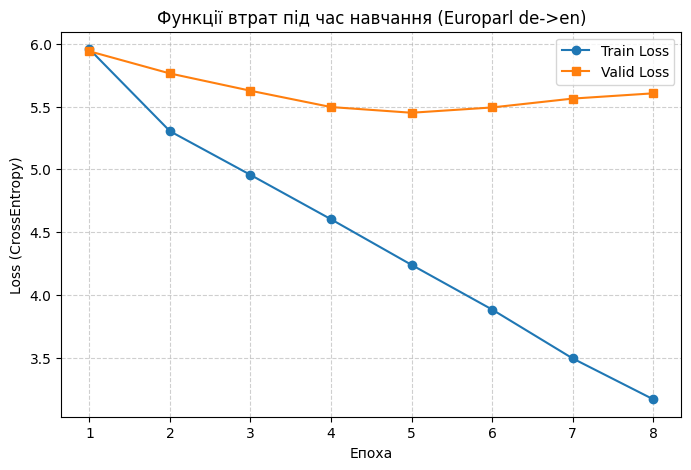

In [27]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, n_epochs + 1), train_losses, label='Train Loss', marker='o')
plt.plot(range(1, n_epochs + 1), valid_losses, label='Valid Loss', marker='s')
plt.xlabel('Епоха')
plt.ylabel('Loss (CrossEntropy)')
plt.title('Функції втрат під час навчання (Europarl de->en)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [28]:
# Завантажуємо найкращу модель
model.load_state_dict(torch.load(model_path, map_location=device))


def translate_sentence(sentence, model, de_nlp, en_vocab, de_vocab, device):
  model.eval()
  if isinstance(sentence, str):
    de_tokens = [token.text.lower() for token in de_nlp.tokenizer(sentence)][
        :MAX_LEN
    ]
  else:
    de_tokens = [tok.lower() for tok in sentence][:MAX_LEN]

  de_tokens = [sos_token] + de_tokens + [eos_token]
  ids = de_vocab.lookup_indices(de_tokens)
  src_tensor = torch.LongTensor(ids).unsqueeze(-1).to(device)

  with torch.no_grad():
    encoder_outputs, hidden = model.encoder(src_tensor)

  inputs = [en_vocab[sos_token]]
  attentions = []

  for _ in range(MAX_LEN):
    inputs_tensor = torch.LongTensor([inputs[-1]]).to(device)
    with torch.no_grad():
      output, hidden, attention = model.decoder(
          inputs_tensor, hidden, encoder_outputs
      )

    attentions.append(attention.squeeze(0).cpu())
    predicted_token = output.argmax(-1).item()
    inputs.append(predicted_token)

    if predicted_token == en_vocab[eos_token]:
      break

  en_tokens = en_vocab.lookup_tokens(inputs)
  attention_matrix = torch.stack(attentions)
  return en_tokens, de_tokens, attention_matrix


def plot_attention_matrix(src_tokens, trg_tokens, attention_matrix, title=''):
  fig, ax = plt.subplots(figsize=(7, 7))
  attn = attention_matrix.squeeze(1).numpy()

  cax = ax.matshow(attn, cmap='bone')
  fig.colorbar(cax)

  ax.set_xticks(np.arange(len(src_tokens)))
  ax.set_yticks(np.arange(len(trg_tokens[1:])))

  ax.set_xticklabels(src_tokens, rotation=90, fontsize=11)
  ax.set_yticklabels(trg_tokens[1:], fontsize=11)
  ax.set_title(title, pad=20)
  plt.tight_layout()
  plt.show()

Приклад #20
Оригінал (DE):  So besteht ein direkter Zusammenhang zwischen unseren Nahrungsmittelprogrammen und strukturellen Reformen in der Landwirtschaft sowie der Linderung der Armut.
Еталон (EN):    Our food programmes are directly related to structural reforms in agriculture as well as poverty alleviation.
Модель (EN):    in order to achieve a balance between our and and and the and the and the and the and the and the and and the and


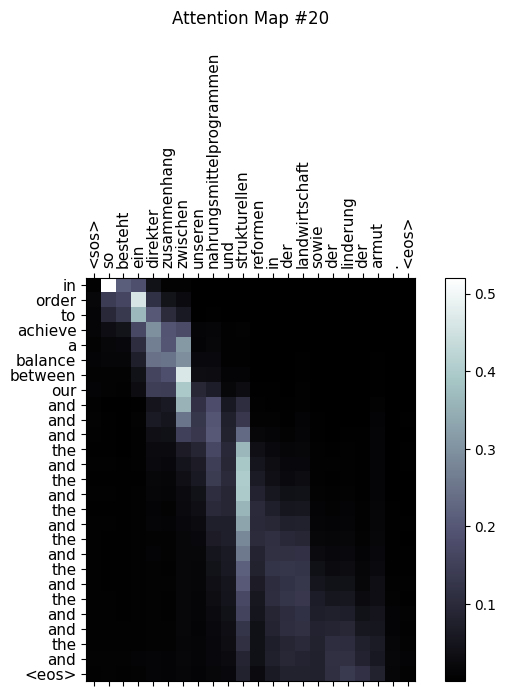

Приклад #100
Оригінал (DE):  Frau Präsidentin! Ist meine Stimme mitgezählt worden?
Еталон (EN):    Madam President, has my vote been counted?
Модель (EN):    madam president , i am very much of my regret that the ?


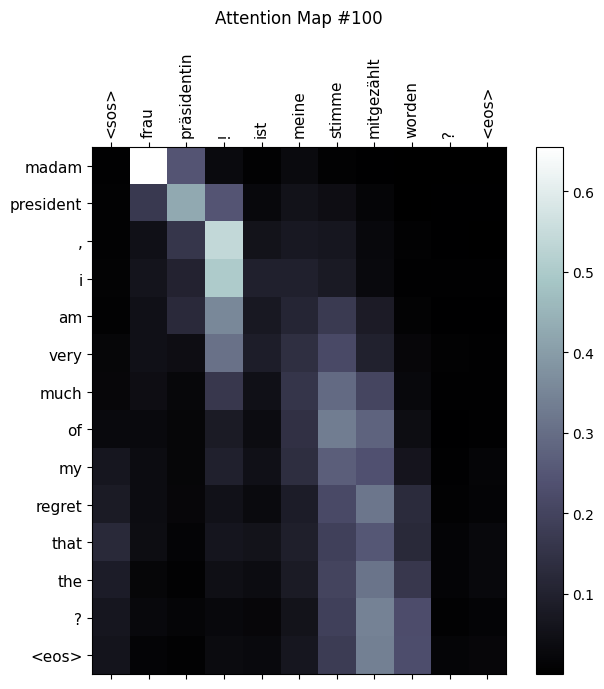

Приклад #1000
Оригінал (DE):  Herr Präsident, Herr Kommissar, liebe Kolleginnen und Kollegen! Meine praktischen Erfahrungen auf dem Balkan während der Zeit meines Militärdienstes lassen mich heute um Ihre Unterstützung der Bemühungen des UN-Generalsekretärs bitten, die Verantwortlichen für den Völkermord in Kambodscha vor ein unabhängiges Gericht unter der Schirmherrschaft der Vereinten Nationen zu stellen.
Еталон (EN):    Mr President, Commissioner, it is because of my experience in the Balkans, when I was there on duty, that I call on you today to support the efforts of the Secretary-General of the United Nations to bring those responsible for the genocide in Cambodia to trial before an independent court under the aegis of the United Nations.
Модель (EN):    mr president , commissioner , ladies and gentlemen , i am very much of the the of the the of the the of the the of the the of the the to the the


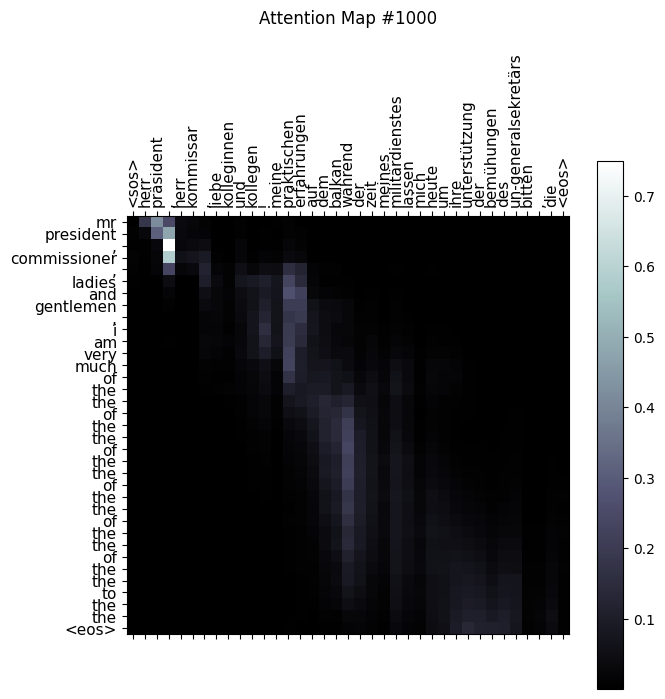

In [30]:
# Тестування
sample_indices = [20, 100, 1000]

for idx in sample_indices:
  sample_de = test_data[idx]['de']
  reference_en = test_data[idx]['en']

  pred_tokens, src_tokens, attention_mat = translate_sentence(
      sample_de, model, de_nlp, en_vocab, de_vocab, device
  )
  pred_sentence = ' '.join(pred_tokens[1:-1])


  print(f'Приклад #{idx}')
  print(f'Оригінал (DE):  {sample_de}')
  print(f'Еталон (EN):    {reference_en}')
  print(f'Модель (EN):    {pred_sentence}')

  plot_attention_matrix(
      src_tokens, pred_tokens, attention_mat, title=f'Attention Map #{idx}'
  )

ВИСНОВКИ

Точка оптимуму - епоха 5 (Valid Loss: 5.451)

До 5-ї епохи обидва графіки (Train та Valid) синхронно спадали. Це була фаза активного засвоєння граматичних конструкцій та лексики мовної пари. На 5-й епосі досягнуто найкращої здатності до генералізації на нових текстах.

Починаючи з 6-ї епохи спостерігаємо перенавчання (Overfitting) , Train Loss продовжив стрімко падати (4.239 - 3.168), тоді як Valid Loss розвернувся і пішов угору (5.451 - 5.494 - 5.564 - 5.606).

Причина: для складної парламентської мови Europarl підмножина у 20 000 речень є відносно невеликою. Мережа вичерпала ресурс узагальнення і почала зазубрювати специфічні формулювання навчального набору.